# Practical 1, Part II: Finite-Difference Solver for Stationary Diffusion

**Materials Simulation Practical 1, Task 5** · Ali Ghelichkhani ([ali.ghelichkhani@fau.de](mailto:ali.ghelichkhani@fau.de)) · Supervisor: Xingchen Tan
Institute of Materials Simulation (WW8), FAU Erlangen-Nürnberg · Winter semester 2026/27

This notebook implements and verifies the finite-difference scheme derived in Part I
(`report/main.pdf`). We solve the stationary diffusion equation

$$
\partial^2_{xx}\rho + P\,\partial^2_{yy}\rho = 0 \qquad \text{on } [0, l_x]\times[0, l_y]
$$

with Dirichlet conditions $\rho = \bar\rho_\mathrm{upper}$ at $y = l_y$ and
$\rho = \bar\rho_\mathrm{lower}$ at $y = 0$, and Neumann conditions on $x = 0$ and $x = l_x$.
The prescribed flux $\bar j = \boldsymbol{j}\cdot\boldsymbol{n}$ is the component along the outward
normal, so $\bar j < 0$ means flux *into* the domain. Equation numbers such as (3.6) refer to Part I.

All quantities are in SI units: concentration in mol m⁻³, flux in mol m⁻² s⁻¹, diffusion
coefficient in m² s⁻¹. Unless stated otherwise we use an isotropic medium ($P = 1$), a square
domain of side $l = 1\,\mathrm{cm}$ and $D = 10^{-9}\,\mathrm{m^2\,s^{-1}}$. The reference flux
$J = 2\times10^{-6}\,\mathrm{mol\,m^{-2}\,s^{-1}}$ produces concentration differences of order
$Jl/D = 20\,\mathrm{mol\,m^{-3}}$.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.linalg import solve_banded

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

L = 1e-2   # domain size l_x = l_y [m]
D = 1e-9   # diffusion coefficient [m^2 s^-1]
J = 2e-6   # reference boundary flux [mol m^-2 s^-1]

## 1 Implementation (Task 5.1)

**Unknowns and numbering.** The Dirichlet rows are eliminated, so the unknowns are the
$N_x(N_y-2)$ nodes between them, numbered row-wise from the top left as in Part I. In
zero-based form this is $k' = rN_x + i'$ with the row index $r$ counted from the top, which is
NumPy's row-major order: the solution vector reshapes directly into an $(N_y-2)\times N_x$ array.

**Assembly in two steps**, as suggested in the script:

1. *Stencil without boundary conditions.* We build the one-dimensional second-difference
   operators $\mathbf{T}_x = \operatorname{tridiag}(-1, 2, -1)$ of size $N_x$ and
   $\mathbf{T}_y = \lambda\operatorname{tridiag}(-1, 2, -1)$ of size $N_y - 2$, with
   $\lambda = P h_x^2/h_y^2$. Their Kronecker sum
   $\mathbf{A} = \mathbf{I}\otimes\mathbf{T}_x + \mathbf{T}_y\otimes\mathbf{I}$ reproduces the
   five-point stencil (3.6) with diagonal $2(1+\lambda)$ and the block-tridiagonal structure (5.3).
   The Kronecker product also avoids the wrap-around coupling between the ends of neighbouring
   mesh rows (Section 3.3).
2. *Boundary rows.* Neumann: eliminating the ghost node replaces $-1$ by $-2$ in the first and
   last row of $\mathbf{T}_x$, eqs. (4.4)–(4.7). Dirichlet: the known rows have no entries in
   $\mathbf{T}_y$, so the matrix needs no change; their values enter the right-hand side.

The right-hand side is $\boldsymbol b_\rho - \boldsymbol b_j$ (eq. 5.1), with $\lambda\bar\rho$
in the first and last row of unknowns and $2h_x\bar j/D$ in the first and last column. Boundary
values can be scalars or node-wise arrays, so arbitrary boundary data are supported.

In [2]:
def assemble_matrix(nx, ny, lam):
    """Coefficient matrix A of eq. (5.1) for nx*(ny-2) unknowns, numbered row-wise from the top left."""
    nr = ny - 2  # rows of unknowns between the two Dirichlet rows
    # Step 1: 1D second differences without boundary conditions
    Tx = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(nx, nx), format="lil")
    Ty = lam * sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(nr, nr))
    # Step 2: Neumann rows, ghost node = mirrored interior neighbour (eqs. 4.4, 4.5).
    # Dirichlet rows are eliminated: Ty has no entries for them, their values go into b_rho.
    Tx[0, 1] = Tx[-1, -2] = -2.0
    return (sp.kron(sp.identity(nr), Tx.tocsr()) + sp.kron(Ty, sp.identity(nx))).tocsc()


def assemble_rhs(nx, ny, hx, lam, D, rho_upper, rho_lower, j_left, j_right):
    """Right-hand side b_rho - b_j of eq. (5.1); boundary values are scalars or node-wise arrays."""
    nr = ny - 2
    b_rho = np.zeros((nr, nx))
    b_rho[0] += lam * np.broadcast_to(rho_upper, nx)
    b_rho[-1] += lam * np.broadcast_to(rho_lower, nx)
    b_j = np.zeros((nr, nx))
    b_j[:, 0] = 2 * hx / D * np.broadcast_to(j_left, nr)
    b_j[:, -1] = 2 * hx / D * np.broadcast_to(j_right, nr)
    return (b_rho - b_j).ravel()


def solve_diffusion(lx, ly, nx, ny, rho_upper, rho_lower, j_left=0.0, j_right=0.0, D=D, P=1.0):
    """Solve d2rho/dx2 + P d2rho/dy2 = 0 on [0, lx] x [0, ly].

    rho_upper, rho_lower: Dirichlet values on y = ly and y = 0 (scalar or array of length nx).
    j_left, j_right: outward normal flux on x = 0 and x = lx (scalar or array of length ny - 2);
        negative values mean flux into the domain.
    Returns X, Y, rho as (ny, nx) arrays in node-numbering order (top row first).
    """
    hx, hy = lx / (nx - 1), ly / (ny - 1)
    lam = P * hx**2 / hy**2
    A = assemble_matrix(nx, ny, lam)
    b = assemble_rhs(nx, ny, hx, lam, D, rho_upper, rho_lower, j_left, j_right)
    inner = spla.spsolve(A, b).reshape(ny - 2, nx)
    rho = np.vstack([np.broadcast_to(rho_upper, (1, nx)), inner, np.broadcast_to(rho_lower, (1, nx))])
    X, Y = np.meshgrid(np.linspace(0, lx, nx), np.linspace(ly, 0, ny))
    return X, Y, rho

**Consistency with Part I.** For the $5\times5$ mesh with $\lambda = 1$ the assembled matrix must
equal eq. (5.2), and scaling the Neumann rows by $1/2$ must make it symmetric (Section 5.2).

[[ 4 -2  0  0  0 -1  0  0  0  0  0  0  0  0  0]
 [-1  4 -1  0  0  0 -1  0  0  0  0  0  0  0  0]
 [ 0 -1  4 -1  0  0  0 -1  0  0  0  0  0  0  0]
 [ 0  0 -1  4 -1  0  0  0 -1  0  0  0  0  0  0]
 [ 0  0  0 -2  4  0  0  0  0 -1  0  0  0  0  0]
 [-1  0  0  0  0  4 -2  0  0  0 -1  0  0  0  0]
 [ 0 -1  0  0  0 -1  4 -1  0  0  0 -1  0  0  0]
 [ 0  0 -1  0  0  0 -1  4 -1  0  0  0 -1  0  0]
 [ 0  0  0 -1  0  0  0 -1  4 -1  0  0  0 -1  0]
 [ 0  0  0  0 -1  0  0  0 -2  4  0  0  0  0 -1]
 [ 0  0  0  0  0 -1  0  0  0  0  4 -2  0  0  0]
 [ 0  0  0  0  0  0 -1  0  0  0 -1  4 -1  0  0]
 [ 0  0  0  0  0  0  0 -1  0  0  0 -1  4 -1  0]
 [ 0  0  0  0  0  0  0  0 -1  0  0  0 -1  4 -1]
 [ 0  0  0  0  0  0  0  0  0 -1  0  0  0 -2  4]]
eigenvalues of A real and positive: True


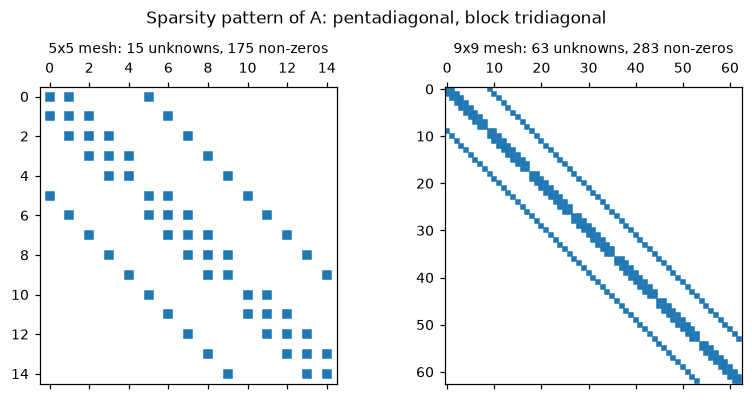

In [3]:
A = assemble_matrix(5, 5, lam=1.0)
print(A.toarray().astype(int))

assert A[0, 1] == -2 and A[1, 0] == -1      # Neumann row couples with -2, the interior row back with -1
assert A[9, 8] == -2 and A[7, 7] == 4 and A[7, 2] == -1
w = np.ones(15)
w[0::5] = w[4::5] = 0.5
WA = sp.diags(w) @ A
assert abs(WA - WA.T).max() < 1e-14         # W A is symmetric
print("eigenvalues of A real and positive:", np.all(np.linalg.eigvals(A.toarray()).real > 0))

fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.6))
for ax, n in zip(axs, [5, 9]):
    M = assemble_matrix(n, n, 1.0)
    ax.spy(M, markersize=5 if n == 5 else 2.5)
    ax.set_title(f"{n}x{n} mesh: {M.shape[0]} unknowns, {M.nnz} non-zeros", fontsize=9)
fig.suptitle("Sparsity pattern of A: pentadiagonal, block tridiagonal")
fig.tight_layout()

In [4]:
def plot_field(ax, X, Y, rho, title, levels=21, flux=False):
    """Filled contours of rho (coordinates in mm); optionally streamlines of j = -D grad(rho)."""
    x, y, r = X[0] * 1e3, Y[::-1, 0] * 1e3, rho[::-1]  # plot with y increasing
    cf = ax.contourf(x, y, r, levels=levels, cmap="viridis")
    if np.ptp(rho) > 1e-9:
        ax.contour(x, y, r, levels=cf.levels, colors="k", linewidths=0.3)
    if flux:
        gy, gx = np.gradient(r, y, x)
        ax.streamplot(x, y, -gx, -gy, color="w", linewidth=0.7, density=0.7, arrowsize=0.8)
    ax.set(title=title, xlabel="$x$ [mm]", ylabel="$y$ [mm]", aspect="equal",
           xlim=(x[0], x[-1]), ylim=(y[0], y[-1]))
    plt.colorbar(cf, ax=ax, label=r"$\rho$ [mol m$^{-3}$]", shrink=0.85)

## 2 Test problems (Task 5.2)

### Test 1: uniform concentration

$\bar j_\mathrm{left} = \bar j_\mathrm{right} = 0$ and
$\bar\rho_\mathrm{upper} = \bar\rho_\mathrm{lower} = 100\,\mathrm{mol\,m^{-3}}$. (The script leaves
the flux value blank; zero flux is the only choice for which the concentration is constant.)

max |rho - 100| = 4.5e-13 mol/m^3


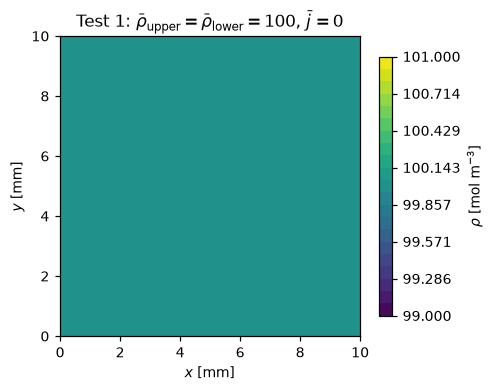

In [5]:
X, Y, rho = solve_diffusion(L, L, 21, 21, rho_upper=100.0, rho_lower=100.0, j_left=0.0, j_right=0.0)
print(f"max |rho - 100| = {np.abs(rho - 100).max():.1e} mol/m^3")
assert np.allclose(rho, 100.0, atol=1e-10)

fig, ax = plt.subplots(figsize=(4.4, 3.6))
plot_field(ax, X, Y, rho, r"Test 1: $\bar\rho_\mathrm{upper}=\bar\rho_\mathrm{lower}=100$, $\bar j=0$",
           levels=np.linspace(99, 101, 22))  # 100 lies inside a band, not on a level

The concentration is $100\,\mathrm{mol\,m^{-3}}$ at every node to round-off. A constant satisfies
the Laplace equation, both Dirichlet conditions and the zero-flux conditions, and the solution is
unique (Section 5.2 of Part I), so this is the exact solution. The scheme reproduces it exactly
because every row of the stencil sums to zero.

### Test 2: linear profile

$\bar\rho_\mathrm{upper} = 100$, $\bar\rho_\mathrm{lower} = 50\,\mathrm{mol\,m^{-3}}$, zero flux.
The exact solution is $\rho(y) = \bar\rho_\mathrm{lower} + (\bar\rho_\mathrm{upper} - \bar\rho_\mathrm{lower})\,y/l_y$.

max |rho - exact| = 3.6e-13 mol/m^3


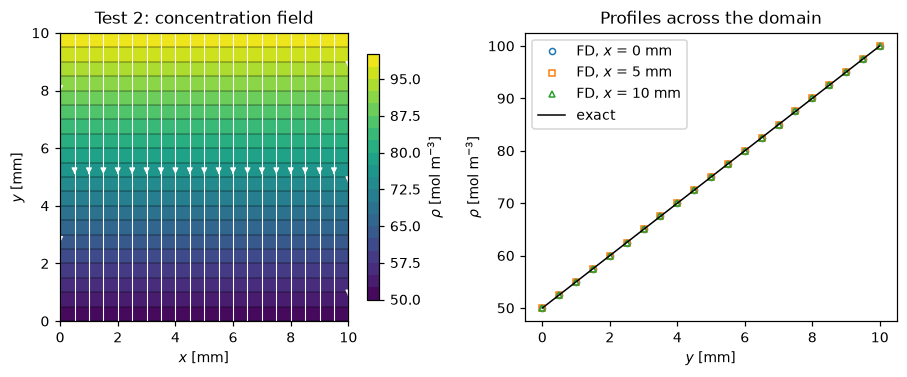

In [6]:
X, Y, rho = solve_diffusion(L, L, 21, 21, rho_upper=100.0, rho_lower=50.0)
exact = 50.0 + 50.0 * Y / L
print(f"max |rho - exact| = {np.abs(rho - exact).max():.1e} mol/m^3")
assert np.allclose(rho, exact, atol=1e-10)

fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.5))
plot_field(axs[0], X, Y, rho, "Test 2: concentration field", flux=True)
for i, mk in [(0, "o"), (10, "s"), (20, "^")]:
    axs[1].plot(Y[:, i] * 1e3, rho[:, i], mk, ms=4, mfc="none", label=f"FD, $x$ = {X[0, i] * 1e3:.0f} mm")
axs[1].plot(Y[:, 0] * 1e3, exact[:, 0], "k-", lw=1, label="exact")
axs[1].set(xlabel="$y$ [mm]", ylabel=r"$\rho$ [mol m$^{-3}$]", title="Profiles across the domain")
axs[1].legend()
fig.tight_layout()

The profile is linear and identical in every column; isolines are horizontal and meet the
zero-flux boundaries at right angles, and the flux lines (white) run straight from the upper to
the lower boundary. The finite-difference solution is exact to round-off: the truncation error
(3.5) vanishes for polynomials of degree at most three (Remark 3.1), and the ghost-node condition
(4.4) is exact for $\partial_x\rho = 0$.

### Test 3: different pairs of concentrations, and a single simulation for all of them

all pairs reproduced from a single unit solution


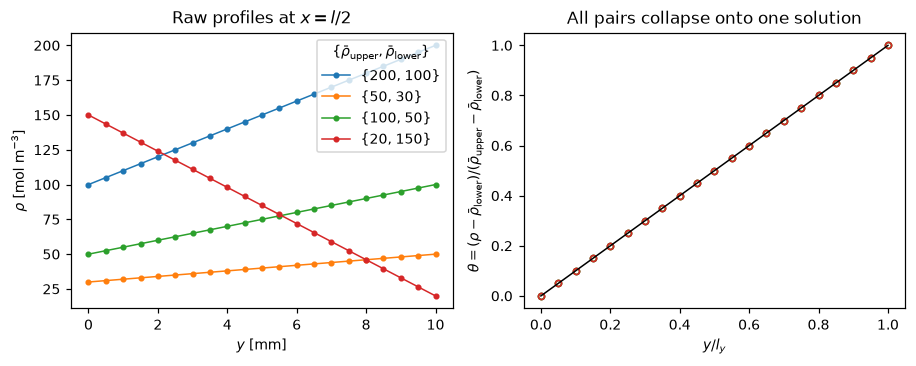

In [7]:
pairs = [(200.0, 100.0), (50.0, 30.0), (100.0, 50.0), (20.0, 150.0)]
nx = ny = 21
hx, lam = L / (nx - 1), 1.0

# A does not depend on the boundary values: factorize once, then solve one unit problem
lu = spla.splu(assemble_matrix(nx, ny, lam))
theta = lu.solve(assemble_rhs(nx, ny, hx, lam, D, 1.0, 0.0, 0.0, 0.0)).reshape(ny - 2, nx)

fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.4))
for ru, rl in pairs:
    X, Y, rho = solve_diffusion(L, L, nx, ny, ru, rl)
    assert np.allclose(rho[1:-1], rl + (ru - rl) * theta)   # one unit solution reproduces every pair
    axs[0].plot(Y[:, 10] * 1e3, rho[:, 10], "o-", ms=3, lw=1, label=f"{{{ru:.0f}, {rl:.0f}}}")
    axs[1].plot(Y[:, 10] / L, (rho[:, 10] - rl) / (ru - rl), "o", ms=4, mfc="none")
axs[1].plot([0, 1], [0, 1], "k-", lw=1)
axs[0].set(xlabel="$y$ [mm]", ylabel=r"$\rho$ [mol m$^{-3}$]", title="Raw profiles at $x = l/2$")
axs[0].legend(title=r"$\{\bar\rho_\mathrm{upper}, \bar\rho_\mathrm{lower}\}$")
axs[1].set(xlabel="$y/l_y$", ylabel=r"$\theta = (\rho-\bar\rho_\mathrm{lower})/(\bar\rho_\mathrm{upper}-\bar\rho_\mathrm{lower})$",
           title="All pairs collapse onto one solution")
fig.tight_layout()
print("all pairs reproduced from a single unit solution")

Every pair yields a linear profile between its two boundary values. Because the problem is
linear in the boundary data, the normalized concentration

$$
\theta = \frac{\rho - \bar\rho_\mathrm{lower}}{\bar\rho_\mathrm{upper} - \bar\rho_\mathrm{lower}}
$$

satisfies the same equation with $\theta = 1$ on the upper boundary, $\theta = 0$ on the lower
boundary and zero flux, independently of the pair. **A single simulation of $\theta$ therefore
describes the behaviour completely:** $\rho = \bar\rho_\mathrm{lower} + (\bar\rho_\mathrm{upper} -
\bar\rho_\mathrm{lower})\,\theta$, as the collapse in the right panel and the assertion confirm.

With non-zero fluxes the same scaling turns the Neumann condition into
$\partial\theta/\partial n = -\Pi$ with the dimensionless flux
$\Pi = \bar j\,l_y / \bigl(D(\bar\rho_\mathrm{upper} - \bar\rho_\mathrm{lower})\bigr)$, so the
normalized solution depends only on $\Pi_\mathrm{left}$, $\Pi_\mathrm{right}$, the aspect ratio
and $P$. Equivalently, by superposition every data set is a linear combination of four unit
solutions (one per boundary). Computationally, the coefficient matrix does not depend on the
boundary values at all, so it is factorized once and each new data set costs only a forward and
backward substitution.

### Test 4: coarse grid versus analytical solution

With zero flux the scheme is exact (Tests 1 to 3), so a meaningful comparison needs non-zero
fluxes. We impose a through-flow, $\bar j_\mathrm{left} = -J$ (inflow) and
$\bar j_\mathrm{right} = +J$ (outflow), with $\bar\rho_\mathrm{upper} = 100$ and
$\bar\rho_\mathrm{lower} = 50\,\mathrm{mol\,m^{-3}}$.

**Analytical solution.** We write $\rho = \bar\rho_\mathrm{lower} + (\bar\rho_\mathrm{upper} -
\bar\rho_\mathrm{lower})\,y/l_y + u$, where $u$ is harmonic, vanishes on the upper and lower
boundaries and carries the Neumann data. Separation of variables with
$k_n = n\pi/l_y$ and the sine series $1 = \sum_{n\,\mathrm{odd}} \frac{4}{n\pi}\sin(k_n y)$ on
$(0, l_y)$ gives

$$
\rho(x,y) = \bar\rho_\mathrm{lower} + (\bar\rho_\mathrm{upper}-\bar\rho_\mathrm{lower})\frac{y}{l_y}
- \sum_{n\ \mathrm{odd}} \frac{4\,\sin(k_n y)}{n\pi\,D\,k_n \sinh(k_n l_x)}
\Bigl[\bar j_\mathrm{right}\cosh(k_n x) + \bar j_\mathrm{left}\cosh\bigl(k_n(l_x - x)\bigr)\Bigr].
$$

Differentiating confirms $\partial_x\rho = -\bar j_\mathrm{right}/D$ at $x = l_x$ and
$\partial_x\rho = +\bar j_\mathrm{left}/D$ at $x = 0$, as required by eq. (4.3). The series is
evaluated with $10^4$ terms in an overflow-safe form; doubling the number of terms changes the
result by less than $10^{-7}\,\mathrm{mol\,m^{-3}}$.

In [8]:
def rho_exact(X, Y, lx, ly, rho_upper, rho_lower, j_left, j_right, D=D, n_terms=10_000, chunk=250):
    """Fourier-series solution for constant Dirichlet values and constant boundary fluxes."""
    xs, ys = X.ravel()[:, None], Y.ravel()[:, None]
    n_odd = np.arange(1, 2 * n_terms, 2)
    u = np.zeros(X.size)
    for s in range(0, n_odd.size, chunk):
        n = n_odd[s:s + chunk][None, :]
        k = n * np.pi / ly
        den = 1 - np.exp(-2 * k * lx)
        cosh_r = (np.exp(k * (xs - lx)) + np.exp(-k * (xs + lx))) / den     # cosh(k x) / sinh(k lx)
        cosh_l = (np.exp(-k * xs) + np.exp(k * (xs - 2 * lx))) / den        # cosh(k (lx - x)) / sinh(k lx)
        u -= (4 / (n * np.pi * D * k) * (j_right * cosh_r + j_left * cosh_l) * np.sin(k * ys)).sum(axis=1)
    return rho_lower + (rho_upper - rho_lower) * Y / ly + u.reshape(X.shape)


bc_flow = dict(rho_upper=100.0, rho_lower=50.0, j_left=-J, j_right=J)
X5, Y5, rho5 = solve_diffusion(L, L, 5, 5, **bc_flow)
ex5 = rho_exact(X5, Y5, L, L, **bc_flow)
assert np.abs(rho_exact(X5, Y5, L, L, **bc_flow, n_terms=20_000) - ex5).max() < 1e-7

np.set_printoptions(precision=3, suppress=True)
print("FD (5x5), rows from top:\n", rho5)
print("analytical:\n", ex5)
print("FD - analytical:\n", rho5 - ex5)
k = np.unravel_index(np.abs(rho5 - ex5).argmax(), rho5.shape)
print(f"largest |error| = {np.abs(rho5 - ex5).max():.3f} mol/m^3 at x = {X5[k] * 1e3:.1f} mm, y = {Y5[k] * 1e3:.1f} mm")

FD (5x5), rows from top:
 [[100.    100.    100.    100.    100.   ]
 [ 92.5    89.375  87.5    85.625  82.5  ]
 [ 81.25   77.5    75.     72.5    68.75 ]
 [ 67.5    64.375  62.5    60.625  57.5  ]
 [ 50.     50.     50.     50.     50.   ]]
analytical:
 [[100.    100.    100.    100.    100.   ]
 [ 93.128  89.539  87.5    85.461  81.872]
 [ 81.753  77.727  75.     72.273  68.247]
 [ 68.128  64.539  62.5    60.461  56.872]
 [ 50.     50.     50.     50.     50.   ]]
FD - analytical:
 [[ 0.     0.     0.     0.     0.   ]
 [-0.628 -0.164  0.     0.164  0.628]
 [-0.503 -0.227  0.     0.227  0.503]
 [-0.628 -0.164  0.     0.164  0.628]
 [ 0.     0.     0.     0.     0.   ]]
largest |error| = 0.628 mol/m^3 at x = 0.0 mm, y = 2.5 mm


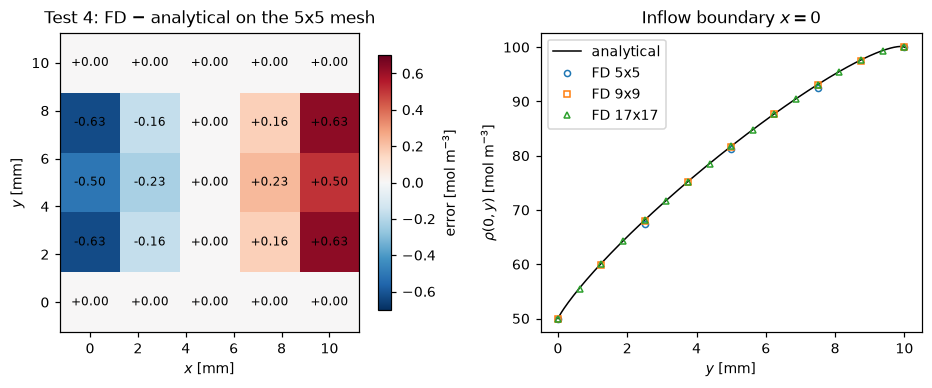

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.6))
err = (rho5 - ex5)[::-1]
im = axs[0].imshow(err, cmap="RdBu_r", vmin=-0.7, vmax=0.7, origin="lower", extent=[-1.25, 11.25, -1.25, 11.25])
for (r, c), e in np.ndenumerate(err):
    axs[0].text(c * 2.5, r * 2.5, f"{e:+.2f}", ha="center", va="center", fontsize=8)
axs[0].set(title="Test 4: FD $-$ analytical on the 5x5 mesh", xlabel="$x$ [mm]", ylabel="$y$ [mm]")
plt.colorbar(im, ax=axs[0], label=r"error [mol m$^{-3}$]", shrink=0.85)

yf = np.linspace(L, 0, 401)[:, None]
axs[1].plot(yf * 1e3, rho_exact(np.zeros_like(yf), yf, L, L, **bc_flow), "k-", lw=1, label="analytical")
for n, mk in [(5, "o"), (9, "s"), (17, "^")]:
    Xn, Yn, rn = solve_diffusion(L, L, n, n, **bc_flow)
    axs[1].plot(Yn[:, 0] * 1e3, rn[:, 0], mk, ms=4, mfc="none", label=f"FD {n}x{n}")
axs[1].set(xlabel="$y$ [mm]", ylabel=r"$\rho(0, y)$ [mol m$^{-3}$]", title="Inflow boundary $x = 0$")
axs[1].legend()
fig.tight_layout()

**Where is the discrepancy largest, and why?** The error vanishes on the Dirichlet rows, where
the values are prescribed, and on the vertical symmetry line $x = l/2$, where the antisymmetric
through-flow contributes nothing. It is largest at the Neumann boundary nodes next to the
corners (nodes 1, 5, 11 and 15 of Part I), where the coarse solution underestimates the rise of
the concentration at the inflow boundary and its drop at the outflow boundary.

The reason is the incompatibility of the boundary conditions at the four corners. Along a
Dirichlet edge the concentration is constant, so $\partial_x\rho = 0$ there, whereas the adjacent
Neumann edge demands $\partial_x\rho = \mp\bar j/D \neq 0$. The exact solution resolves this
conflict with a corner singularity of the form $r\ln r$ (with $r$ the distance from the corner):
the concentration gradient diverges logarithmically and the second derivatives like $1/r$.
The truncation error (3.5) involves fourth derivatives and is therefore unbounded near the
corners, and the steep boundary layer at the inflow and outflow edges (right panel) cannot be
represented by a few nodes.

### Test 5: mesh refinement and convergence

We refine square meshes from $5\times5$ to $257\times257$ nodes and measure the maximum and
root-mean-square nodal errors for two problems:

* **(a)** the through-flow problem of Test 4, which contains the corner singularities;
* **(b)** a smooth reference solution without singularities,
  $\rho = 75 + 25\cos(\pi x/l)\cosh(\pi y/l)/\cosh\pi$. It is harmonic, satisfies zero flux at
  $x = 0$ and $x = l$, and supplies non-uniform Dirichlet values on the upper and lower boundaries.

In [10]:
def rho_smooth(X, Y):
    return 75.0 + 25.0 * np.cos(np.pi * X / L) * np.cosh(np.pi * Y / L) / np.cosh(np.pi)


Ns = [5, 9, 17, 33, 65, 129, 257]
rows = []
for n in Ns:
    t0 = time.perf_counter()
    X, Y, r = solve_diffusion(L, L, n, n, **bc_flow)
    t_solve = time.perf_counter() - t0
    ea = r - rho_exact(X, Y, L, L, **bc_flow)
    x = np.linspace(0, L, n)
    X, Y, r = solve_diffusion(L, L, n, n, rho_smooth(x, L), rho_smooth(x, 0.0))
    eb = r - rho_smooth(X, Y)
    rms = lambda e: np.sqrt(np.mean(e**2))
    rows.append((n, L / (n - 1), np.abs(ea).max(), rms(ea), np.abs(eb).max(), rms(eb), t_solve))
res = np.array(rows)

print(f"{'N':>5} {'h [mm]':>8} {'(a) max':>10} {'(a) rms':>10} {'(b) max':>10} {'(b) rms':>10} {'solve [s]':>10}")
for n, h, *e, t in rows:
    print(f"{n:5d} {h * 1e3:8.4f} " + " ".join(f"{v:10.2e}" for v in e) + f" {t:10.4f}")
orders = np.log2(res[:-1, 2:6] / res[1:, 2:6])
print("\nobserved orders log2(e_h / e_h/2), columns (a) max, (a) rms, (b) max, (b) rms:")
print(orders.round(2))

    N   h [mm]    (a) max    (a) rms    (b) max    (b) rms  solve [s]
    5   2.5000   6.28e-01   3.03e-01   4.30e-01   2.13e-01     0.0007
    9   1.2500   2.79e-01   9.07e-02   1.13e-01   5.68e-02     0.0005
   17   0.6250   1.35e-01   2.56e-02   2.90e-02   1.44e-02     0.0006
   33   0.3125   6.72e-02   6.99e-03   7.27e-03   3.62e-03     0.0013
   65   0.1562   3.35e-02   1.87e-03   1.82e-03   9.06e-04     0.0054
  129   0.0781   1.68e-02   4.94e-04   4.55e-04   2.27e-04     0.0265
  257   0.0391   8.38e-03   1.30e-04   1.14e-04   5.66e-05     0.1409

observed orders log2(e_h / e_h/2), columns (a) max, (a) rms, (b) max, (b) rms:
[[1.17 1.74 1.93 1.91]
 [1.04 1.83 1.96 1.98]
 [1.01 1.87 2.   1.99]
 [1.   1.9  2.   2.  ]
 [1.   1.92 2.   2.  ]
 [1.   1.93 2.   2.  ]]


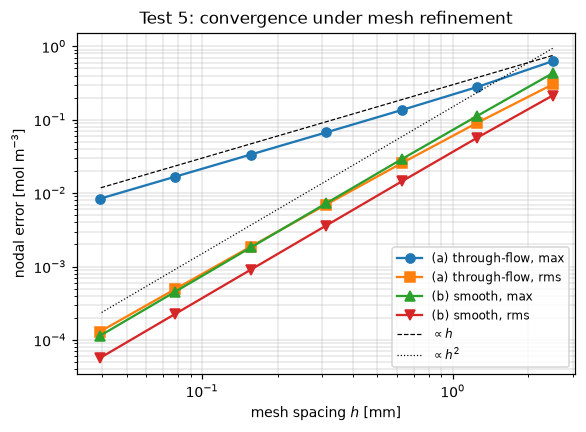

In [11]:
fig, ax = plt.subplots(figsize=(5.4, 4.0))
h = res[:, 1] * 1e3
ax.loglog(h, res[:, 2], "o-", label="(a) through-flow, max")
ax.loglog(h, res[:, 3], "s-", label="(a) through-flow, rms")
ax.loglog(h, res[:, 4], "^-", label="(b) smooth, max")
ax.loglog(h, res[:, 5], "v-", label="(b) smooth, rms")
ax.loglog(h, 0.3 * h, "k--", lw=0.8, label=r"$\propto h$")
ax.loglog(h, 0.15 * h**2, "k:", lw=0.8, label=r"$\propto h^2$")
ax.set(xlabel="mesh spacing $h$ [mm]", ylabel=r"nodal error [mol m$^{-3}$]", title="Test 5: convergence under mesh refinement")
ax.legend(fontsize=8)
ax.grid(which="both", lw=0.3)
fig.tight_layout()

Increasing the number of nodes reduces the error monotonically. For the smooth problem (b) both
error norms decrease by a factor of four per halving of $h$, i.e. the scheme converges with
second order, as predicted by the truncation error (3.5). For the through-flow problem (a) the
root-mean-square error also approaches second order (observed orders tend towards 2 from below,
the deficit being a logarithmic factor from the singularity), whereas the maximum error, always
found at the node next to a corner, converges only with first order. The corner singularity
thus pollutes the solution locally but barely affects the global accuracy. The price of
refinement is computational: the number of unknowns grows as $h^{-2}$ and the solution time of
the sparse direct solver grows somewhat faster (last column of the table).

### Test 6: speeding up the case $\bar j_\mathrm{left} = \bar j_\mathrm{right} = 0$

With zero flux and constant boundary concentrations, the problem is invariant under translation
in $x$, so the solution does not depend on $x$. The column-replicated solution of the
one-dimensional problem $\rho_{j-1} - 2\rho_j + \rho_{j+1} = 0$ satisfies every equation of the
two-dimensional system (the $x$ differences vanish and the ghost nodes mirror their neighbours),
and since the two-dimensional solution is unique, the two coincide. This allows three
increasingly radical speed-ups that do not change the result:

1. solve the tridiagonal 1D problem with $N_y - 2$ unknowns in $\mathcal{O}(N_y)$ operations
   instead of the 2D problem with $N_x(N_y - 2)$ unknowns;
2. use $N_y = 3$, because the scheme is exact for linear profiles, and interpolate linearly;
3. skip the solve entirely and evaluate the closed form, combined with the unit solution of
   Test 3 for arbitrary pairs of concentrations.

In [12]:
nx = ny = 401
ru, rl = 120.0, 35.0

t0 = time.perf_counter()
X, Y, rho_2d = solve_diffusion(L, L, nx, ny, ru, rl)
t_2d = time.perf_counter() - t0

t0 = time.perf_counter()
ab = np.zeros((3, ny - 2))
ab[0, 1:], ab[1, :], ab[2, :-1] = -1.0, 2.0, -1.0   # banded storage of tridiag(-1, 2, -1)
b = np.zeros(ny - 2)
b[0], b[-1] = ru, rl
rho_1d = np.concatenate([[ru], solve_banded((1, 1), ab, b), [rl]])
t_1d = time.perf_counter() - t0

t0 = time.perf_counter()
rho_cf = rl + (ru - rl) * Y[:, 0] / L
t_cf = time.perf_counter() - t0

assert np.allclose(rho_2d, rho_1d[:, None]) and np.allclose(rho_1d, rho_cf)
print(f"2D sparse solve ({nx * (ny - 2)} unknowns): {t_2d * 1e3:8.2f} ms")
print(f"1D banded solve ({ny - 2} unknowns):     {t_1d * 1e3:8.3f} ms   speed-up x{t_2d / t_1d:.0f}")
print(f"closed form:                       {t_cf * 1e3:8.3f} ms")
print(f"max |2D - 1D| = {np.abs(rho_2d - rho_1d[:, None]).max():.1e} mol/m^3")

2D sparse solve (159999 unknowns):   422.07 ms
1D banded solve (399 unknowns):        0.809 ms   speed-up x522
closed form:                          0.030 ms
max |2D - 1D| = 1.3e-11 mol/m^3


All three approaches give the same concentrations to round-off, while the cost drops by orders of
magnitude. The reduction requires $x$-independent data: non-uniform boundary concentrations or
non-zero fluxes break the translation invariance, and the full two-dimensional problem must be
solved.

### Test 7: different boundary conditions

We keep $\bar\rho_\mathrm{upper} = 100$ and $\bar\rho_\mathrm{lower} = 50\,\mathrm{mol\,m^{-3}}$ and
vary the fluxes. Test 5 shows that $101\times101$ nodes ($h = 0.1\,\mathrm{mm}$) give a
root-mean-square error below $10^{-3}\,\mathrm{mol\,m^{-3}}$ and a maximum error of about
$0.02\,\mathrm{mol\,m^{-3}}$ even next to the corners, negligible against the concentration
range of $50\,\mathrm{mol\,m^{-3}}$, at a solution time of a fraction of a second.
White lines in the plots are streamlines of the diffusion flux $\boldsymbol j = -D\nabla\rho$.

case                                         min  at (x, y) [mm]      max  at (x, y) [mm]   outward flux per unit depth [nmol m^-1 s^-1]
(a) through-flow: in left, out right       49.89    (10.0,  0.1)   100.11    ( 0.0,  9.9)   upper  -50.0, lower  +50.0, sides   +0.0, sum -8.8e-12
(b) inflow through both sides              50.00    ( 0.0,  0.0)   100.17    (10.0,  9.8)   upper  -30.0, lower  +70.0, sides  -40.0, sum -7.9e-12
(c) outflow through both sides             49.83    ( 0.0,  0.2)   100.00    ( 0.0, 10.0)   upper  -70.0, lower  +30.0, sides  +40.0, sum -8.5e-12


(d) strong inflow left, no flux right      50.00    ( 0.0,  0.0)   102.28    ( 0.0,  9.1)   upper  -30.0, lower  +70.0, sides  -40.0, sum -8.5e-12


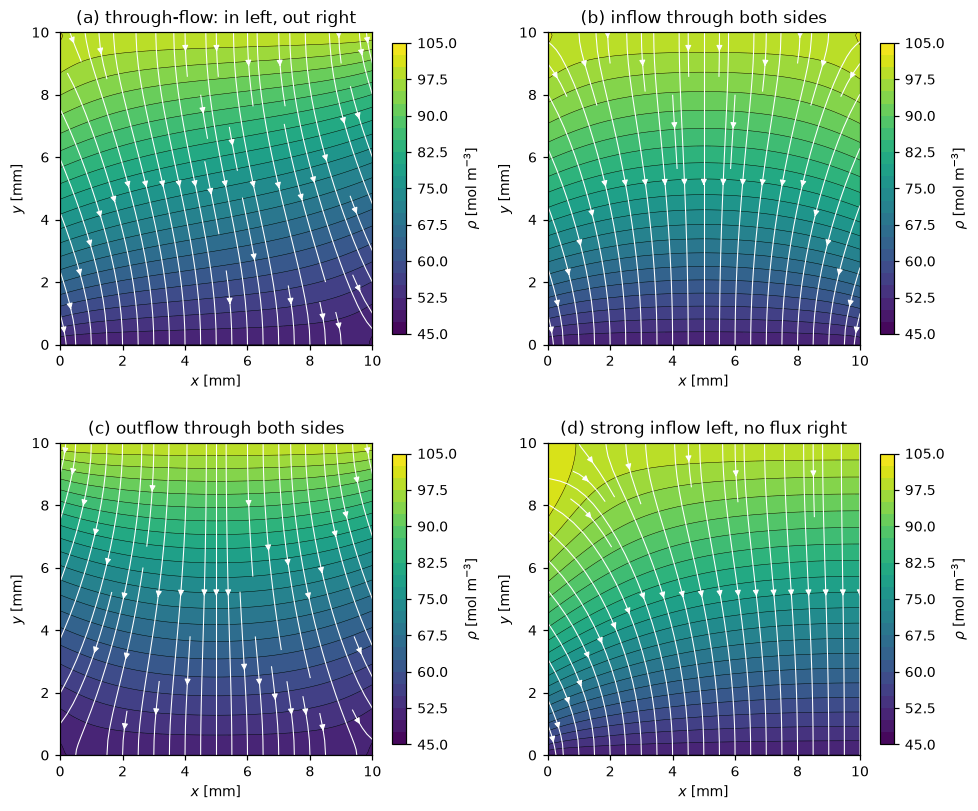

In [13]:
cases = {
    "(a) through-flow: in left, out right": (-J, J),
    "(b) inflow through both sides": (-J, -J),
    "(c) outflow through both sides": (J, J),
    "(d) strong inflow left, no flux right": (-2 * J, 0.0),
}
n = 101
fig, axs = plt.subplots(2, 2, figsize=(9.0, 7.6))
print(f"{'case':40s} {'min':>7s} {'at (x, y) [mm]':>15s} {'max':>8s} {'at (x, y) [mm]':>15s}   "
      "outward flux per unit depth [nmol m^-1 s^-1]")
for ax, (name, (jl, jr)) in zip(axs.ravel(), cases.items()):
    X, Y, rho = solve_diffusion(L, L, n, n, 100.0, 50.0, jl, jr)
    plot_field(ax, X, Y, rho, name, levels=np.linspace(45, 105, 25), flux=True)
    # Net outward flux through each boundary: second-order one-sided gradients on the Dirichlet edges
    h = L / (n - 1)
    out_upper = np.trapezoid(-D * (3 * rho[0] - 4 * rho[1] + rho[2]) / (2 * h), dx=h)
    out_lower = np.trapezoid(D * (-3 * rho[-1] + 4 * rho[-2] - rho[-3]) / (2 * h), dx=h)
    out_sides = (jl + jr) * L
    total = out_upper + out_lower + out_sides
    assert abs(total) < 1e-6 * D * 50 / L * L   # stationary state: no net accumulation
    kmin = np.unravel_index(rho.argmin(), rho.shape)
    kmax = np.unravel_index(rho.argmax(), rho.shape)
    at = lambda k: f"({X[k] * 1e3:4.1f}, {Y[k] * 1e3:4.1f})"
    print(f"{name:40s} {rho.min():7.2f} {at(kmin):>15s} {rho.max():8.2f} {at(kmax):>15s}   "
          f"upper {out_upper * 1e9:+6.1f}, lower {out_lower * 1e9:+6.1f}, sides {out_sides * 1e9:+6.1f}, sum {total * 1e9:+.1e}")
fig.tight_layout()

**Interpretation.** Without lateral fluxes, diffusion carries matter from the upper to the
lower boundary along straight vertical flux lines (Test 2). The lateral fluxes superimpose a
horizontal component on this background:

* **(a) Through-flow.** Matter entering on the left raises the concentration there, matter
  leaving on the right lowers it; the isolines tilt and the flux lines bend from left to right.
  Since the net lateral flux is zero, the fluxes through the upper and lower boundaries are the
  same as in Test 2.
* **(b) Inflow through both sides.** The concentration rises towards both lateral boundaries.
  The added matter must leave through the Dirichlet boundaries, so less matter enters at the top
  and more leaves at the bottom (table). The maximum exceeds $\bar\rho_\mathrm{upper}$ and lies on
  a lateral boundary next to an upper corner.
* **(c) Outflow through both sides** is the mirror image of (b): the minimum falls below
  $\bar\rho_\mathrm{lower}$ on a lateral boundary next to a lower corner.
* **(d) One-sided inflow** combines (a) and (b): a pronounced concentration maximum forms at the
  upper end of the inflow boundary, and the right boundary acts as a symmetry plane.

**Behaviour towards the boundaries.** On the Dirichlet boundaries the isolines run parallel to
the boundary, since the concentration is constant there. On the Neumann boundaries the normal
derivative is fixed, $\partial\rho/\partial n = -\bar j/D$: for zero flux the isolines meet the
boundary at right angles, while a prescribed flux tilts them so that the gradient points away
from an inflow and towards an outflow boundary. Towards the corners the two conditions conflict
(Test 4): the isolines crowd together, the flux lines converge and the flux density becomes
singular, so the flux density through the Dirichlet boundaries peaks next to the corners. In
every case the extrema lie on the
boundary, as required by the maximum principle (Remark 3.1), and the net outward flux through all
four boundaries vanishes to round-off, as it must in a stationary state without sources.

## 3 Summary

* The solver assembles the system of Part I as a Kronecker sum of one-dimensional operators,
  supports arbitrary domain sizes, node numbers and node-wise boundary data, and reproduces the
  matrix (5.2) and its properties exactly.
* Tests 1 and 2: uniform and linear solutions are reproduced to round-off.
* Test 3: by linearity, one normalized simulation (or one factorization of $\mathbf{A}$) covers all
  pairs of boundary concentrations.
* Test 4: on a coarse mesh the largest errors occur at the Neumann nodes next to the corners,
  where incompatible boundary conditions cause a singularity.
* Test 5: second-order convergence for smooth solutions; with corner singularities the maximum
  error converges with first order, the root-mean-square error still nearly with second order.
* Test 6: for zero lateral flux the problem reduces exactly to one dimension, or to a closed form.
* Test 7: lateral fluxes tilt the isolines at the Neumann boundaries and concentrate the flux at
  the corners, while the global mass balance is satisfied to round-off.